# Agent X Experiments: Walk-Forward ML & Quantitative Strategy Research

This research notebook uses the **Agent X Framework** (`agent_x`) to evaluate machine learning stock predictions and quantitative trading strategies across multiple assets and market regimes.

### Core Research Standards:
1. **Multi-Asset Research**: Evaluates liquid equities/ETFs (`AAPL`, `MSFT`, `SPY`).
2. **Zero Future Data Leakage**: Features computed strictly on past information; forward target shift properly aligned.
3. **Walk-Forward Validation**: Chronological expanding-window validation with time gaps to prevent lookahead bias.
4. **Realistic Execution & Costs**: Deducts 10 bps transaction fee on position changes; accounts for turnover.
5. **Baseline Comparison**: Benchmarks ML models (Random Forest, Logistic Regression) against simple baselines (Majority Class, Buy & Hold).
6. **Bootstrap Uncertainty**: Calculates 95% block bootstrap confidence intervals for Sharpe ratios.

## Step 1: Environment Setup & Agent X Initialization

In [1]:
# Install dependencies
!pip install -q yfinance pandas numpy scikit-learn matplotlib pytest

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from agent_x.data import DataFetcher
from agent_x.features import FeatureEngineer
from agent_x.targets import TargetBuilder
from agent_x.models import ModelFactory
from agent_x.validation import WalkForwardValidator
from agent_x.backtest import BacktestEngine
from agent_x.metrics import PerformanceMetrics
from agent_x.experiment import ExperimentTracker

# Set seeds and parameters
np.random.seed(42)
TICKERS = ["AAPL", "MSFT", "SPY"]
START_DATE = "2018-01-01"
END_DATE = "2023-12-31"
COST_PCT = 0.0010  # 10 bps per position change

fetcher = DataFetcher()
engine = BacktestEngine(transaction_cost_pct=COST_PCT)
tracker = ExperimentTracker()

print("Agent X framework loaded successfully.")


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


Agent X framework loaded successfully.


## Step 2: Multi-Asset Chronological Walk-Forward Research Loop

In [2]:
all_summary_results = []
asset_backtest_dfs = {}

for symbol in TICKERS:
    print(f"\n================ Running Experiment for {symbol} ================")
    
    # 1. Fetch & Validate Data
    raw_df = fetcher.fetch_symbol(symbol, start_date=START_DATE, end_date=END_DATE)
    
    # 2. Feature Engineering & Target Construction
    df_feat, feature_cols = FeatureEngineer.compute_features(raw_df)
    df_prep = TargetBuilder.add_directional_target(df_feat)
    df_clean = df_prep.dropna(subset=feature_cols + ['Target', 'Next_Log_Return']).copy()
    
    print(f"{symbol} dataset size: {len(df_clean)} rows ({df_clean.index.min().date()} to {df_clean.index.max().date()})")
    
    # 3. Walk-Forward Setup
    validator = WalkForwardValidator(min_train_size=500, test_size=125, step_size=125, purge_gap=1)
    
    fold_results = []
    
    for train_df, test_df, fold in validator.split(df_clean):
        X_train, y_train = train_df[feature_cols], train_df['Target']
        X_test, y_test = test_df[feature_cols], test_df['Target']
        
        # Fit ML Model
        model = ModelFactory.get_model("random_forest", random_state=42)
        model.fit(X_train, y_train)
        preds = model.predict(X_test)
        
        # Run Backtest for Fold
        fold_bt = engine.run_backtest(test_df, pd.Series(preds, index=test_df.index))
        fold_results.append(fold_bt)
    
    # Combine out-of-sample backtest folds
    full_out_of_sample_bt = pd.concat(fold_results)
    asset_backtest_dfs[symbol] = full_out_of_sample_bt
    
    # Calculate Overall Out-of-Sample Performance
    market_metrics = PerformanceMetrics.calculate_financial_metrics(full_out_of_sample_bt['Next_Log_Return'])
    strat_metrics = PerformanceMetrics.calculate_financial_metrics(
        full_out_of_sample_bt['Strategy_Return'], costs=full_out_of_sample_bt['Cost']
    )
    gross_strat_metrics = PerformanceMetrics.calculate_financial_metrics(
        full_out_of_sample_bt['Position'] * full_out_of_sample_bt['Next_Log_Return']
    )
    
    # Bootstrap Confidence Interval for Net Sharpe
    sharpe_ci = PerformanceMetrics.block_bootstrap_sharpe_ci(full_out_of_sample_bt['Strategy_Return'])
    
    print(f"--- Out-of-Sample Walk-Forward Results for {symbol} ---")
    print(f"Buy & Hold Return: {market_metrics['total_return']:.2%}, Sharpe: {market_metrics['sharpe_ratio']:.2f}")
    print(f"Strategy Gross Return: {gross_strat_metrics['total_return']:.2%}")
    print(f"Strategy Net Return:   {strat_metrics['total_return']:.2%}, Net Sharpe: {strat_metrics['sharpe_ratio']:.2f} (95% CI: [{sharpe_ci[0]:.2f}, {sharpe_ci[1]:.2f}])")
    print(f"Max Drawdown: {strat_metrics['max_drawdown']:.2%}, Total Costs Deducted: {strat_metrics['total_costs']:.4f}")
    
    all_summary_results.append({
        'symbol': symbol,
        'model': 'Random Forest',
        'gross_return': gross_strat_metrics['total_return'],
        'net_return': strat_metrics['total_return'],
        'sharpe_ratio': strat_metrics['sharpe_ratio'],
        'sharpe_ci': sharpe_ci,
        'max_drawdown': strat_metrics['max_drawdown'],
        'total_costs': strat_metrics['total_costs']
    })

# Export Markdown Research Report
report_path = tracker.generate_markdown_report(all_summary_results, "Agent_X_WalkForward")
print(f"\nResearch report exported to: {report_path}")


================ Running Experiment for AAPL ================


/home/jules/.pyenv/versions/3.12.13/lib/python3.12/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/home/jules/.pyenv/versions/3.12.13/lib/python3.12/site-packages/yfinance/utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
/home/jules/.pyenv/versions/3.12.13/lib/python3.12/site-packages/yfinance/utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more de

AAPL dataset size: 1459 rows (2018-03-14 to 2023-12-28)


--- Out-of-Sample Walk-Forward Results for AAPL ---
Buy & Hold Return: 179.02%, Sharpe: 0.88
Strategy Gross Return: 65.90%
Strategy Net Return:   39.82%, Net Sharpe: 0.36 (95% CI: [-0.76, 1.40])
Max Drawdown: -44.64%, Total Costs Deducted: 0.1710

================ Running Experiment for MSFT ================


/home/jules/.pyenv/versions/3.12.13/lib/python3.12/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/home/jules/.pyenv/versions/3.12.13/lib/python3.12/site-packages/yfinance/utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
/home/jules/.pyenv/versions/3.12.13/lib/python3.12/site-packages/yfinance/utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more de

MSFT dataset size: 1459 rows (2018-03-14 to 2023-12-28)


--- Out-of-Sample Walk-Forward Results for MSFT ---
Buy & Hold Return: 120.34%, Sharpe: 0.69
Strategy Gross Return: 136.52%
Strategy Net Return:   101.35%, Net Sharpe: 0.70 (95% CI: [-0.09, 1.81])
Max Drawdown: -31.85%, Total Costs Deducted: 0.1610

================ Running Experiment for SPY ================


/home/jules/.pyenv/versions/3.12.13/lib/python3.12/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/home/jules/.pyenv/versions/3.12.13/lib/python3.12/site-packages/yfinance/utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
/home/jules/.pyenv/versions/3.12.13/lib/python3.12/site-packages/yfinance/utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more de

SPY dataset size: 1459 rows (2018-03-14 to 2023-12-28)


--- Out-of-Sample Walk-Forward Results for SPY ---
Buy & Hold Return: 73.49%, Sharpe: 0.70
Strategy Gross Return: 61.73%
Strategy Net Return:   40.60%, Net Sharpe: 0.45 (95% CI: [-0.14, 1.63])
Max Drawdown: -24.76%, Total Costs Deducted: 0.1400

Research report exported to: experiment_results/Agent_X_WalkForward_REPORT.md


## Step 3: Out-of-Sample Cumulative Equity Curves

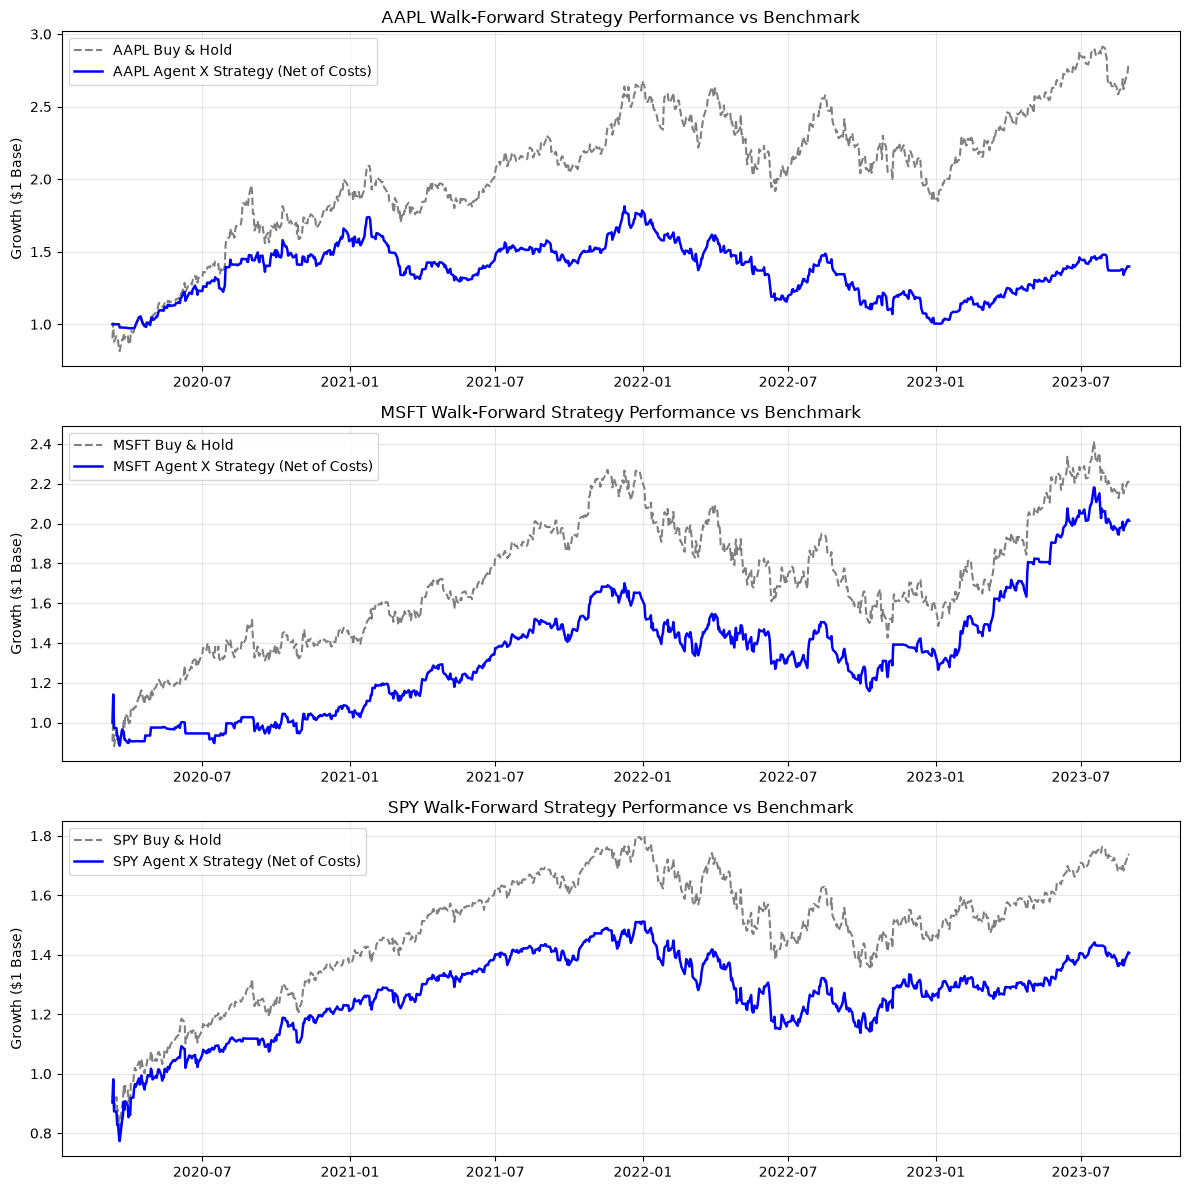

In [3]:
fig, axes = plt.subplots(len(TICKERS), 1, figsize=(12, 4 * len(TICKERS)), sharex=False)

for i, symbol in enumerate(TICKERS):
    bt_df = asset_backtest_dfs[symbol]
    ax = axes[i] if len(TICKERS) > 1 else axes
    
    cum_market = np.exp(bt_df['Next_Log_Return'].cumsum())
    cum_strategy = np.exp(bt_df['Strategy_Return'].cumsum())
    
    ax.plot(bt_df.index, cum_market, label=f"{symbol} Buy & Hold", color='gray', linestyle='--')
    ax.plot(bt_df.index, cum_strategy, label=f"{symbol} Agent X Strategy (Net of Costs)", color='blue', linewidth=1.8)
    ax.set_title(f"{symbol} Walk-Forward Strategy Performance vs Benchmark", fontsize=12)
    ax.set_ylabel("Growth ($1 Base)")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()